# Farmer-Herder Conflict Risk in Southern Chad — Full Pipeline

Capstone project, BSc Software Engineering (Machine Learning), African Leadership University.

This notebook runs the complete pipeline, step by step, with its outputs, and ends with the
full source code of the `chadrisk` package. It is generated by `scripts/make_notebook.py` from
the scripts and the package, which remain the reference implementation.

**Research question.** Do satellite-derived indicators of pasture conditions, rainfall and the
crop calendar improve the prediction of farmer-herder conflict risk in southern Chad, compared
with conflict history alone?

**Steps**
1. Download conflict events (ACLED API) — *skipped by default, data already downloaded*
2. Validated labels and target variable
3. Exploratory analysis
4. Department x month panel
5. Dashboard database
6. Satellite indicators (Google Earth Engine) — *skipped by default, already extracted*
7. Feature table (no look-ahead)
8. Training and evaluation: research model (conflict history up to the previous month) and
   operational model (only information available at forecast time), monthly and quarterly
9. Automated tests
10. Source code of the `chadrisk` package

> Ethics: aggregated department-level data only, no ethnic or religious variables. Raw ACLED
> data are not redistributed (licence). The tool supports human decisions; it does not make them.


In [1]:
import subprocess
import sys
from pathlib import Path

# Project root (works whether the notebook is opened from notebooks/ or from the project root)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))  # makes the chadrisk package importable

# Optional steps (they need credentials and take time; their outputs are already in data/)
RUN_DOWNLOAD = False   # step 1: re-download ACLED events (needs ACLED credentials in .env)
RUN_GEE = False        # step 6: update satellite indicators (needs Earth Engine)
print("Project root:", ROOT)

Project root: C:\Users\RICHARD\Capstone project


## 1. Download conflict events (ACLED API)

```text
Step 1 — Download all ACLED events for Chad (2015-01-01 -> 2025-10-02).

Requires ACLED_USERNAME and ACLED_PASSWORD in .env (see .env.example).
```

In [2]:
if RUN_DOWNLOAD:
    import os
    import sys

    from dotenv import load_dotenv

    from chadrisk.config import PATHS
    from chadrisk.data.acled import AcledClient, AcledError

    load_dotenv(PATHS.root / ".env")
    try:
        client = AcledClient(os.getenv("ACLED_USERNAME"), os.getenv("ACLED_PASSWORD"))
        events = client.fetch("Chad", "2015-01-01", "2025-10-02")
    except (ValueError, AcledError) as error:
        sys.exit(f"ACLED download failed: {error}")
    if events.empty:
        sys.exit("No events received: check the parameters against the ACLED API guide.")

    PATHS.raw.mkdir(parents=True, exist_ok=True)
    events.to_csv(PATHS.acled_raw, index=False)
    print(f"{len(events)} events saved to {PATHS.acled_raw}")
    print(f"Period: {events['event_date'].min()} -> {events['event_date'].max()}")
else:
    print('Skipped (set RUN_DOWNLOAD = True to run this step).')

Skipped (set RUN_DOWNLOAD = True to run this step).


## 2. Validated labels and target variable

```text
Step 2 — Apply the validated labels and build the target variable.
```

In [3]:
from chadrisk.config import PATHS
from chadrisk.data.labels import LabelledEvents

events = LabelledEvents.from_files(PATHS.acled_raw, PATHS.manual_labels).build()
events.to_csv(PATHS.labelled_events, index=False)

fh = events[events["target_fh"] == 1]
print("Label distribution:")
print(events["label"].value_counts().to_string())
print(f"\nConfirmed farmer-herder conflicts: {len(fh)} | south: {fh['is_south'].sum()} "
      f"({fh['is_south'].mean():.0%}) | fatalities: {fh['fatalities'].sum():.0f}")
print("\nBy province:")
print(fh.groupby("admin1_norm").agg(events=("event_id_cnty", "size"),
                                     fatalities=("fatalities", "sum"))
      .sort_values("events", ascending=False).to_string())

precision, recall = LabelledEvents.keyword_agreement(events)
print(f"\nKeyword filter vs manual labels: precision {precision:.0%}, recall {recall:.0%}")

# Blind validation sample: never overwrite one that has already been annotated
if PATHS.validation_sample.exists():
    print(f"\n{PATHS.validation_sample.name} already exists (annotations preserved).")
else:
    LabelledEvents.validation_sample(events).to_csv(PATHS.validation_sample, index=False)
    print(f"\nValidation sample written: {PATHS.validation_sample}")

Label distribution:
label
NO     1334
FH      154
AMB      80
REL      25

Confirmed farmer-herder conflicts: 154 | south: 112 (73%) | fatalities: 827

By province:
                   events  fatalities
admin1_norm                          
Logone Oriental        31          99
Moyen-Chari            22          86
Logone Occidental      15          87
Mandoul                14          38
Ouaddai                14         142
Mayo Kebbi Ouest       11          32
Guera                  11          76
Mayo Kebbi Est         10          58
Tandjile                9          73
Batha                   6          52
Salamat                 4          38
Hadjer-Lamis            2          21
Chari Baguirmi          2           4
Lac                     1          12
Kanem                   1           1
Sila                    1           8

Keyword filter vs manual labels: precision 60%, recall 99%

validation_sample.csv already exists (annotations preserved).


## 3. Exploratory analysis

```text
Step 3 — Exploratory analysis of ACLED data for Chad (2015-2025), using the validated labels.
Goal: document the concentration, trend and seasonality of farmer-herder conflict
in the south (figures for the report).
```

Events per year (all ACLED events, Chad):
year
2015     40
2016     40
2017     26
2018     83
2019    211
2020    159
2021    251
2022    269
2023    187
2024    169
2025    158

Event types:
event_type
Violence against civilians    405
Battles                       380
Protests                      377
Strategic developments        193
Riots                         172
Explosions/Remote violence     66

Geographic precision (1-2 = precise, 3 = province level):
geo_precision
1    970
2    541
3     82


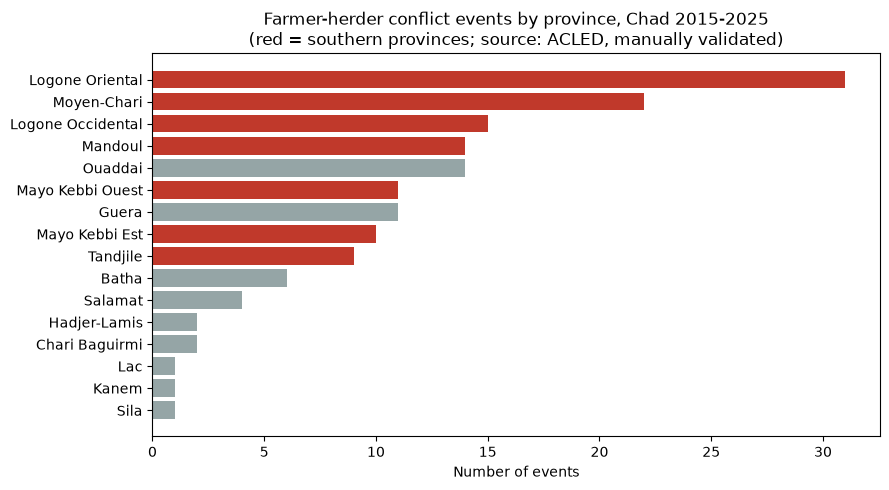

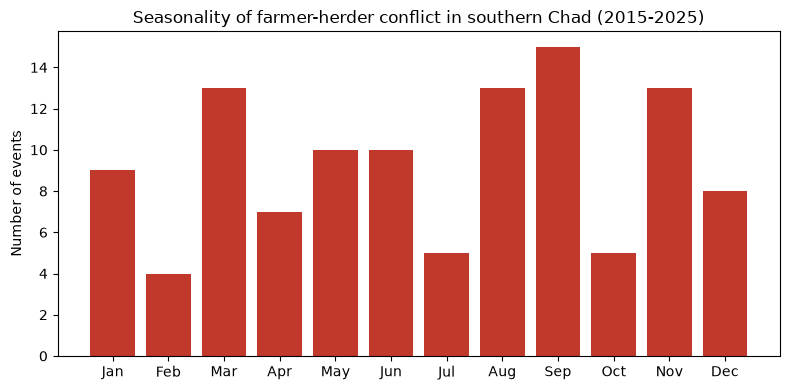

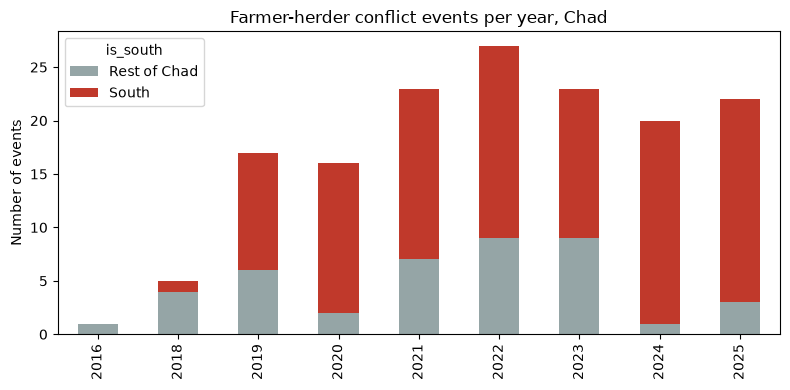

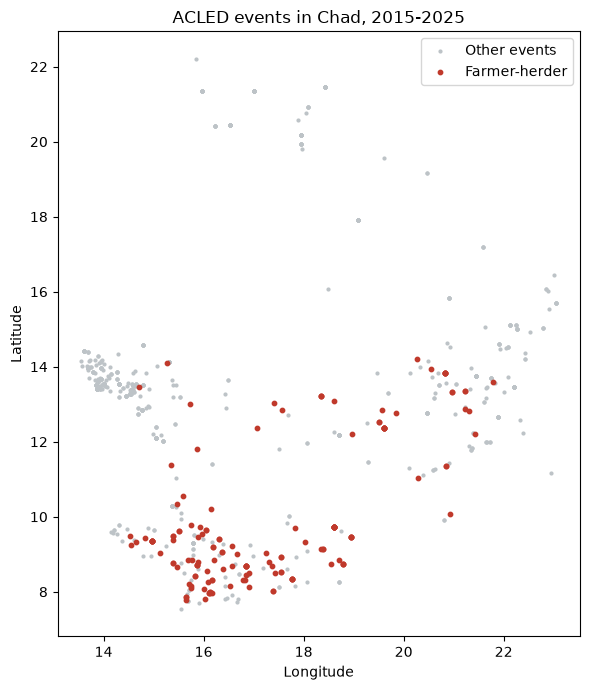


Figures saved to C:\Users\RICHARD\Capstone project\reports\figures


In [4]:
import matplotlib


import matplotlib.pyplot as plt  # noqa: E402
import pandas as pd  # noqa: E402

from chadrisk.config import PATHS  # noqa: E402

DATA = PATHS.labelled_events
FIG_DIR = PATHS.figures
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA, parse_dates=["event_date"])
fh = df[df["target_fh"] == 1]

print("Events per year (all ACLED events, Chad):")
print(df.groupby("year").size().to_string())
print("\nEvent types:")
print(df["event_type"].value_counts().to_string())
print("\nGeographic precision (1-2 = precise, 3 = province level):")
print(df["geo_precision"].value_counts().sort_index().to_string())

by_prov = (
    fh.groupby("admin1_norm")
    .agg(events=("event_id_cnty", "size"), fatalities=("fatalities", "sum"),
         south=("is_south", "first"))
    .sort_values("events", ascending=False)
)
season = fh[fh["is_south"]].groupby("month").size().reindex(range(1, 13), fill_value=0)
yearly = (fh.groupby(["year", "is_south"]).size().unstack(fill_value=0)
          .rename(columns={True: "South", False: "Rest of Chad"}))

# Figure 1: events by province
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#c0392b" if s else "#95a5a6" for s in by_prov["south"]]
ax.barh(by_prov.index[::-1], by_prov["events"][::-1], color=colors[::-1])
ax.set_xlabel("Number of events")
ax.set_title("Farmer-herder conflict events by province, Chad 2015-2025\n"
             "(red = southern provinces; source: ACLED, manually validated)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fh_by_province.png", dpi=150)
plt.show()

# Figure 2: seasonality in the south
fig, ax = plt.subplots(figsize=(8, 4))
labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
ax.bar(labels, season.values, color="#c0392b")
ax.set_ylabel("Number of events")
ax.set_title("Seasonality of farmer-herder conflict in southern Chad (2015-2025)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fh_south_seasonality.png", dpi=150)
plt.show()

# Figure 3: yearly trend
ax = yearly.plot(kind="bar", stacked=True, color=["#95a5a6", "#c0392b"], figsize=(8, 4))
ax.set_ylabel("Number of events")
ax.set_xlabel("")
ax.set_title("Farmer-herder conflict events per year, Chad")
plt.tight_layout()
plt.savefig(FIG_DIR / "fh_yearly_trend.png", dpi=150)
plt.show()

# Figure 4: map of events
fig, ax = plt.subplots(figsize=(6, 7))
other = df[df["target_fh"] == 0]
ax.scatter(other["longitude"], other["latitude"], s=4, c="#bdc3c7", label="Other events")
ax.scatter(fh["longitude"], fh["latitude"], s=10, c="#c0392b", label="Farmer-herder")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("ACLED events in Chad, 2015-2025")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "map_events.png", dpi=150)
plt.show()

print(f"\nFigures saved to {FIG_DIR}")

## 4. Department x month panel

```text
Step 4 — Build the department x month panel of southern Chad (2017-01 -> 2025-09).

2017-2018 are burn-in years for the lagged history features; modelling starts in 2019.
```

In [5]:
import pandas as pd

from chadrisk.config import CONFLICT_DATA_END, PANEL_START, PATHS
from chadrisk.data.geography import Geography
from chadrisk.data.panel import PanelBuilder

geography = Geography.from_files(PATHS.external / "tcd_adm1.geojson",
                                 PATHS.external / "tcd_adm2.geojson")
south = geography.region()
south.to_file(PATHS.south_departments, driver="GeoJSON")

events = geography.assign_events(pd.read_csv(PATHS.labelled_events))
print(f"{len(south)} southern departments | events outside every department: "
      f"{events['dept_id'].isna().sum()}")

panel = PanelBuilder(south, PANEL_START, CONFLICT_DATA_END).build(events)
panel.to_csv(PATHS.panel, index=False)
study = panel[panel["year"] >= 2019]
print(f"Panel: {len(panel)} rows | department-months (2019+) with a conflict: "
      f"{study['y_fh'].sum()} ({study['y_fh'].mean():.1%})")

26 southern departments | events outside every department: 0
Panel: 2730 rows | department-months (2019+) with a conflict: 74 (3.5%)


## 5. Dashboard database

```text
Step 5 — Create / refresh the dashboard database (data/app.db).
```

In [6]:
import geopandas as gpd
import pandas as pd

from chadrisk.config import PATHS, STUDY_START_YEAR
from chadrisk.storage import RiskRepository

repository = RiskRepository(PATHS.database)
repository.create_schema()
repository.replace_departments(gpd.read_file(PATHS.south_departments))
panel = pd.read_csv(PATHS.panel)
repository.replace_panel(panel[panel["year"] >= STUDY_START_YEAR])
for table, n in repository.counts().items():
    print(f"{table:12s}: {n} rows")

departments : 26 rows
panel       : 2106 rows
features    : 2236 rows
predictions : 1560 rows


## 6. Satellite indicators (Google Earth Engine)

```text
Step 6 — Extract (or update) the monthly satellite indicators with Google Earth Engine.

Only the months missing from data/processed/satellite_features.csv are extracted, up to the
last month complete in both CHIRPS and MODIS (detected automatically, or --end YYYY-MM).

Requires EE_PROJECT in .env and a one-time `earthengine authenticate`.
```

In [7]:
if RUN_GEE:
    import argparse
    import os

    import geopandas as gpd
    import pandas as pd
    from dotenv import load_dotenv

    from chadrisk.config import NORTH_PROVINCES, PATHS
    from chadrisk.data.geography import Geography
    from chadrisk.data.satellite import SatelliteExtractor

    parser = argparse.ArgumentParser()
    parser.add_argument("--end", default=None, help="last month to extract (YYYY-MM)")
    args = parser.parse_args([])

    load_dotenv(PATHS.root / ".env")
    geography = Geography.from_files(PATHS.external / "tcd_adm1.geojson",
                                     PATHS.external / "tcd_adm2.geojson")
    north = geography.provinces[geography.provinces["province"].isin(NORTH_PROVINCES)]
    if len(north) != len(NORTH_PROVINCES):
        raise SystemExit("northern province not found in the boundaries")

    extractor = SatelliteExtractor(os.getenv("EE_PROJECT"),
                                   gpd.read_file(PATHS.south_departments),
                                   north.dissolve().geometry.iloc[0])
    end = pd.Period(args.end, freq="M") if args.end else extractor.last_complete_month()
    print(f"Last month to extract: {end}")

    existing = pd.read_csv(PATHS.satellite) if PATHS.satellite.exists() else None
    table = extractor.update(existing, end)
    if table is existing:
        print("Nothing to extract: the satellite table is already up to date.")
    else:
        table.to_csv(PATHS.satellite, index=False)
        print(f"{PATHS.satellite}: {len(table)} rows, up to {table['ym'].max()}")
else:
    print('Skipped (set RUN_GEE = True to run this step).')

Skipped (set RUN_GEE = True to run this step).


## 7. Feature table (no look-ahead)

```text
Step 7 — Build the feature table (no look-ahead).

Feature groups:
    h_      conflict history up to month t-1 (research model)
    o_      conflict history up to month t-13 (operational model: ACLED 12-month delay)
    h_month seasonality
    south_ / north_  satellite indicators of month t-1 (if the satellite table exists)
```

In [8]:
import geopandas as gpd
import pandas as pd

from chadrisk.config import ACLED_DELAY_MONTHS, PATHS
from chadrisk.data.geography import Geography
from chadrisk.features import (ConflictHistoryFeatures, FeatureTableBuilder,
                               SatelliteFeatures, SeasonalFeatures)

panel = pd.read_csv(PATHS.panel)
south = gpd.read_file(PATHS.south_departments)
data_end = pd.Period(panel["ym"].max(), freq="M")

groups = [ConflictHistoryFeatures(shift=1, prefix="h_", short_windows=True),
          ConflictHistoryFeatures(shift=1 + ACLED_DELAY_MONTHS, prefix="o_",
                                  short_windows=False),
          SeasonalFeatures()]
horizon_end = data_end + 1
if PATHS.satellite.exists():
    satellite = pd.read_csv(PATHS.satellite)
    groups.append(SatelliteFeatures(satellite, lag=1))
    # forecasts are possible up to the month after the last satellite month, as long as the
    # delayed conflict history (t-13) is still inside the conflict data
    horizon_end = min(pd.Period(satellite["ym"].max(), freq="M") + 1,
                      data_end + 1 + ACLED_DELAY_MONTHS)
else:
    print("No satellite table yet: research model A only.")

builder = FeatureTableBuilder(groups, Geography.neighbours(south),
                              Geography.same_province(south))
features = builder.build(panel, horizon_end)
features.to_csv(PATHS.features, index=False)
print(f"features.csv: {len(features)} rows | conflict data end: {data_end} | "
      f"forecast rows up to: {horizon_end}")

  + conflict history up to t-1 (h_*): 11 features


  + conflict history up to t-13 (o_*): 8 features
  + seasonality: 2 features
  + satellite indicators of month t-1: 10 features


features.csv: 3068 rows | conflict data end: 2025-09 | forecast rows up to: 2026-10


## 8. Training and evaluation

Each run uses `chadrisk.experiment.Experiment` (selection on 2019-2023 by rolling origin, single evaluation on 2024 - Sept 2025) and `chadrisk.reporting.ExperimentReporter` (result files, figures, dashboard predictions). The code of `scripts/train_models.py` is shown below, then run for the four configurations.

```python
import argparse

import pandas as pd

from chadrisk.config import PATHS
from chadrisk.experiment import MODES, UNITS, Experiment, ExperimentConfig
from chadrisk.reporting import ExperimentReporter
from chadrisk.storage import RiskRepository

parser = argparse.ArgumentParser(description=__doc__,
                                 formatter_class=argparse.RawDescriptionHelpFormatter)
parser.add_argument("--mode", choices=MODES, default="research")
parser.add_argument("--unit", choices=UNITS, default="quarter")
parser.add_argument("--fixed-model", default=None,
                    help="model used for the predictions instead of the automatic selection "
                         "(design choice, documented in the model card)")
args = parser.parse_args([])

config = ExperimentConfig(mode=args.mode, unit=args.unit, fixed_model=args.fixed_model)
experiment = Experiment(config, pd.read_csv(PATHS.features))
print(f"{config.tag}: selection 2019-2023 = {len(experiment.selection_data)} rows "
      f"({experiment.selection_data['y_fh'].sum()} positives) | test 2024-2025 = "
      f"{len(experiment.test)} rows ({experiment.test['y_fh'].sum()} positives)")

result = experiment.run()
ExperimentReporter(PATHS, RiskRepository(PATHS.database)).save(result)

pd.set_option("display.width", 200)
print(result.metrics[["model", "val_pr_auc", "pr_auc", "pr_auc_lo", "pr_auc_hi", "roc_auc",
                      "recall_top10"]].round(3).to_string(index=False))
print(f"Automatic selection: {result.auto_selected} | used for predictions: {result.used}")
print(result.tiers[["tier", "ranks", "conflict_rate"]].round(3).to_string(index=False))
print(f"Forecast saved for {result.forecast['ym'].iloc[0]}")
```

### Research model, quarterly

In [9]:
r = subprocess.run([sys.executable, str(ROOT / 'scripts' / 'train_models.py'), *['--mode', 'research', '--unit', 'quarter']],
                   capture_output=True, text=True, cwd=ROOT)
print(r.stdout[-4000:] or r.stderr[-4000:])

research_quarter: selection 2019-2023 = 520 rows (47 positives) | test 2024-2025 = 182 rows (20 positives)
           model  val_pr_auc  pr_auc  pr_auc_lo  pr_auc_hi  roc_auc  recall_top10
rule_history_12m         NaN   0.178      0.094      0.362    0.651          0.20
        logreg_A       0.158   0.210      0.110      0.363    0.650          0.10
       xgboost_A       0.165   0.151      0.102      0.231    0.490          0.10
        logreg_B       0.147   0.244      0.119      0.391    0.670          0.20
       xgboost_B       0.218   0.171      0.075      0.373    0.628          0.10
        logreg_C       0.142   0.243      0.129      0.370    0.676          0.20
       xgboost_C       0.259   0.125      0.065      0.224    0.559          0.05
Automatic selection: xgboost_C | used for predictions: xgboost_C
      tier ranks  conflict_rate
     Top 5   1-5          0.143
Ranks 6-10  6-10          0.114
  Priority  1-10          0.129
     Lower 11-26          0.098
Forecast sav

### Research model, monthly

In [10]:
r = subprocess.run([sys.executable, str(ROOT / 'scripts' / 'train_models.py'), *['--mode', 'research', '--unit', 'month']],
                   capture_output=True, text=True, cwd=ROOT)
print(r.stdout[-4000:] or r.stderr[-4000:])

research_month: selection 2019-2023 = 1560 rows (53 positives) | test 2024-2025 = 546 rows (21 positives)
           model  val_pr_auc  pr_auc  pr_auc_lo  pr_auc_hi  roc_auc  recall_top10
rule_history_12m         NaN   0.065      0.036      0.121    0.651         0.190
        logreg_A       0.122   0.068      0.039      0.160    0.627         0.095
       xgboost_A       0.053   0.051      0.029      0.100    0.525         0.190
        logreg_B       0.120   0.054      0.032      0.113    0.609         0.095
       xgboost_B       0.106   0.050      0.027      0.120    0.550         0.143
        logreg_C       0.125   0.064      0.037      0.172    0.587         0.190
       xgboost_C       0.111   0.041      0.025      0.073    0.528         0.048
Automatic selection: logreg_C | used for predictions: logreg_C
      tier ranks  conflict_rate
     Top 5   1-5          0.067
Ranks 6-10  6-10          0.048
  Priority  1-10          0.057
     Lower 11-26          0.027
Forecast saved 

### Operational model, quarterly (dashboard outlook)

In [11]:
r = subprocess.run([sys.executable, str(ROOT / 'scripts' / 'train_models.py'), *['--mode', 'operational', '--unit', 'quarter', '--fixed-model', 'logreg_OB']],
                   capture_output=True, text=True, cwd=ROOT)
print(r.stdout[-4000:] or r.stderr[-4000:])

operational_quarter: selection 2019-2023 = 520 rows (47 positives) | test 2024-2025 = 182 rows (20 positives)
           model  val_pr_auc  pr_auc  pr_auc_lo  pr_auc_hi  roc_auc  recall_top10
rule_history_12m         NaN   0.189      0.109      0.369    0.591          0.25
       logreg_OA       0.148   0.110      0.081      0.176    0.460          0.05
      xgboost_OA       0.241   0.189      0.076      0.328    0.423          0.10
       logreg_OB       0.141   0.214      0.106      0.412    0.663          0.25
      xgboost_OB       0.188   0.113      0.071      0.212    0.519          0.00
Automatic selection: xgboost_OA | used for predictions: logreg_OB
      tier ranks  conflict_rate
     Top 5   1-5          0.200
Ranks 6-10  6-10          0.200
  Priority  1-10          0.200
     Lower 11-26          0.054
Forecast saved for 2026-10



### Operational model, monthly

In [12]:
r = subprocess.run([sys.executable, str(ROOT / 'scripts' / 'train_models.py'), *['--mode', 'operational', '--unit', 'month']],
                   capture_output=True, text=True, cwd=ROOT)
print(r.stdout[-4000:] or r.stderr[-4000:])

operational_month: selection 2019-2023 = 1560 rows (53 positives) | test 2024-2025 = 546 rows (21 positives)
           model  val_pr_auc  pr_auc  pr_auc_lo  pr_auc_hi  roc_auc  recall_top10
rule_history_12m         NaN   0.064      0.037      0.143    0.571         0.238
       logreg_OA       0.098   0.054      0.028      0.166    0.491         0.238
      xgboost_OA       0.095   0.039      0.025      0.083    0.449         0.095
       logreg_OB       0.104   0.059      0.034      0.155    0.542         0.190
      xgboost_OB       0.153   0.038      0.024      0.064    0.503         0.048
Automatic selection: xgboost_OB | used for predictions: xgboost_OB
      tier ranks  conflict_rate
     Top 5   1-5          0.048
Ranks 6-10  6-10          0.010
  Priority  1-10          0.029
     Lower 11-26          0.045
Forecast saved for 2026-10



### Current outlook (operational model)

In [13]:
from chadrisk.config import PATHS
from chadrisk.storage import RiskRepository

repo = RiskRepository(PATHS.database)
preds = repo.predictions().merge(repo.departments()[['dept_id', 'department', 'province']], on='dept_id')
outlook = preds[preds['model'].str.endswith('operational_quarter_forecast')]
outlook = outlook.sort_values('risk', ascending=False).reset_index(drop=True)
outlook.index += 1
print('Quarter starting', outlook['ym'].iloc[0])
outlook[['department', 'province', 'risk']].head(10)

Quarter starting 2026-10


,department,province,risk
1,Monts de Lam,Logone Oriental,0.808007
2,La Nya Pendé,Logone Oriental,0.773900
3,La Nya,Logone Oriental,0.762330
4,Kouh Ouest,Logone Oriental,0.761659
5,Dodjé,Logone Occidental,0.731792
6,La Pendé,Logone Oriental,0.702765
7,Kouh Est,Logone Oriental,0.669401
8,Barh-Sara,Mandoul,0.585989
9,Mandoul Oriental,Mandoul,0.532360
10,Bahr-Köh,Moyen-Chari,0.495014


## 9. Automated tests

Unit tests (each class, on small synthetic data) and integration tests (the real pipeline outputs and the dashboard).

In [14]:
r = subprocess.run([sys.executable, '-m', 'pytest', '-q', '--color=no', '-p', 'no:cacheprovider', str(ROOT / 'tests')],
                   capture_output=True, text=True, cwd=ROOT)
print(r.stdout[-3000:])

......................................................................   [100%]
70 passed in 47.76s



## 10. Source code of the `chadrisk` package

For reading. The dashboard code is in `app/` (run with `streamlit run app/app.py`).

### `chadrisk/__init__.py`

```python
"""
chadrisk — estimating farmer-herder conflict risk in southern Chad.

Package layout:
    config       paths and project-wide constants
    data         data access and preparation (ACLED, labels, geography, panel, satellite)
    features     feature engineering (one class per feature group)
    models       risk models sharing one interface (logistic, XGBoost, baseline rule)
    evaluation   metrics with bootstrap intervals, rolling-origin selection, priority levels
    experiment   one training/evaluation run (research or operational, month or quarter)
    reporting    report files and figures
    storage      SQLite repository used by the dashboard

Sub-packages are imported explicitly (e.g. ``from chadrisk.storage import RiskRepository``) so
that the dashboard only loads lightweight modules.
"""

__version__ = "1.0.0"
```

### `chadrisk/config.py`

```python
"""Project paths and constants, defined once and shared by every module."""

from dataclasses import dataclass
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]


@dataclass(frozen=True)
class Paths:
    """File locations of the project. Tests can pass another root to work in isolation."""

    root: Path = ROOT

    @property
    def raw(self) -> Path:
        return self.root / "data" / "raw"

    @property
    def processed(self) -> Path:
        return self.root / "data" / "processed"

    @property
    def external(self) -> Path:
        return self.root / "data" / "external"

    @property
    def reports(self) -> Path:
        return self.root / "reports"

    @property
    def figures(self) -> Path:
        return self.reports / "figures"

    @property
    def database(self) -> Path:
        return self.root / "data" / "app.db"

    @property
    def acled_raw(self) -> Path:
        return self.raw / "acled_chad_2015_2025.csv"

    @property
    def manual_labels(self) -> Path:
        return self.processed / "manual_labels.csv"

    @property
    def labelled_events(self) -> Path:
        return self.processed / "acled_chad_labeled.csv"

    @property
    def validation_sample(self) -> Path:
        return self.processed / "validation_sample.csv"

    @property
    def south_departments(self) -> Path:
        return self.processed / "south_departments.geojson"

    @property
    def panel(self) -> Path:
        return self.processed / "panel_dept_month.csv"

    @property
    def satellite(self) -> Path:
        return self.processed / "satellite_features.csv"

    @property
    def features(self) -> Path:
        return self.processed / "features.csv"


PATHS = Paths()

# Provinces, as spelled in geoBoundaries (boundaries) and in ACLED (event records)
SOUTH_PROVINCES = ("Logone Occidental", "Logone Oriental", "Mandoul", "Moyen-Chari",
                   "Tandjilé", "Mayo-Kebbi Est", "Mayo-Kebbi Ouest")
SOUTH_PROVINCES_ACLED = ("Logone Occidental", "Logone Oriental", "Mandoul", "Moyen-Chari",
                         "Tandjile", "Mayo Kebbi Est", "Mayo Kebbi Ouest")
NORTH_PROVINCES = ("Batha", "Guéra", "Salamat", "Ouaddaï")  # herd departure zones

# Time frame
PANEL_START = "2017-01"   # 2017-2018: burn-in for lagged history features only
CONFLICT_DATA_END = "2025-09"  # ACLED Research tier: 12-month publication delay
STUDY_START_YEAR = 2019
VALIDATION_YEARS = (2021, 2022, 2023)  # rolling-origin model selection
TEST_START_YEAR = 2024
ACLED_DELAY_MONTHS = 12

# Columns describing the outcome of the predicted period: never allowed as features
OUTCOME_COLUMNS = frozenset({"n_fh", "n_broad", "n_all_events", "fatalities_fh", "y_fh",
                             "y_broad"})

# Keyword filter used only to compare with the manual classification
KEYWORDS = (r"herder|herdsm|pastoral|cattle|livestock|transhuman|nomad|grazing|"
            r"farmer|crop|field|farm|camel|cow|oxen|herd")

SEED = 42
N_DEPARTMENTS = 26
```

### `chadrisk/data/__init__.py`

```python
"""Data access and preparation: ACLED events, labels, geography, panel, satellite data."""
```

### `chadrisk/data/acled.py`

```python
"""Client for the ACLED API (OAuth authentication and paginated download)."""

import pandas as pd
import requests


class AcledError(RuntimeError):
    """Raised when the ACLED API refuses a request."""


class AcledClient:
    """Downloads ACLED events for one country and period.

    Credentials are passed in (read from .env by the caller) and never stored on disk.
    """

    TOKEN_URL = "https://acleddata.com/oauth/token"
    API_URL = "https://acleddata.com/api/acled/read"

    def __init__(self, username: str, password: str, page_size: int = 5000,
                 session: requests.Session | None = None):
        if not username or not password:
            raise ValueError("ACLED username and password are required")
        self._username = username
        self._password = password
        self._page_size = page_size
        self._session = session or requests.Session()
        self._token: str | None = None

    def _authenticate(self) -> str:
        resp = self._session.post(self.TOKEN_URL, timeout=60, data={
            "username": self._username, "password": self._password,
            "grant_type": "password", "client_id": "acled"})
        if resp.status_code != 200:
            raise AcledError(f"Authentication failed ({resp.status_code}): {resp.text[:300]}")
        return resp.json()["access_token"]

    def fetch(self, country: str, start_date: str, end_date: str) -> pd.DataFrame:
        """All events for `country` between two dates (YYYY-MM-DD), across result pages."""
        self._token = self._token or self._authenticate()
        headers = {"Authorization": f"Bearer {self._token}"}
        rows, page = [], 1
        while True:
            params = {"_format": "json", "country": country,
                      "event_date": f"{start_date}|{end_date}",
                      "event_date_where": "BETWEEN", "limit": self._page_size, "page": page}
            resp = self._session.get(self.API_URL, headers=headers, params=params, timeout=120)
            if resp.status_code != 200:
                raise AcledError(f"API error, page {page} ({resp.status_code}): "
                                 f"{resp.text[:300]}")
            data = resp.json().get("data", [])
            rows.extend(data)
            if len(data) < self._page_size:
                break
            page += 1
        return pd.DataFrame(rows)
```

### `chadrisk/data/geography.py`

```python
"""Administrative geography: provinces, departments, event assignment and neighbourhoods."""

from pathlib import Path

import geopandas as gpd
import pandas as pd

from chadrisk.config import SOUTH_PROVINCES


class Geography:
    """Province (ADM1) and department (ADM2) boundaries of Chad (geoBoundaries, 2019)."""

    def __init__(self, provinces: gpd.GeoDataFrame, departments: gpd.GeoDataFrame):
        self.provinces = provinces.rename(columns={"shapeName": "province"})[
            ["province", "geometry"]]
        departments = departments.rename(columns={"shapeName": "department",
                                                  "shapeID": "dept_id"})
        self.departments = departments[["department", "dept_id", "geometry"]].copy()
        self.departments["province"] = self._province_of(self.departments)

    @classmethod
    def from_files(cls, adm1_path: Path, adm2_path: Path) -> "Geography":
        return cls(gpd.read_file(adm1_path), gpd.read_file(adm2_path))

    def _province_of(self, departments: gpd.GeoDataFrame) -> pd.Series:
        """Province containing each department (tested on an interior point)."""
        points = departments.copy()
        points["geometry"] = departments.representative_point()
        return gpd.sjoin(points, self.provinces, predicate="within")["province"]

    def region(self, provinces=SOUTH_PROVINCES) -> gpd.GeoDataFrame:
        """Departments of the given provinces."""
        region = self.departments[self.departments["province"].isin(provinces)]
        missing = set(provinces) - set(region["province"])
        if missing:
            raise ValueError(f"provinces not found in the boundaries: {sorted(missing)}")
        return region.reset_index(drop=True)

    def assign_events(self, events: pd.DataFrame) -> pd.DataFrame:
        """Adds dept_id to each event by spatial join on its coordinates.

        ACLED admin2 names and geoBoundaries names do not match, so coordinates are used.
        """
        points = gpd.GeoDataFrame(
            events, geometry=gpd.points_from_xy(events["longitude"], events["latitude"]),
            crs="EPSG:4326")
        joined = gpd.sjoin(points, self.departments[["dept_id", "geometry"]],
                           predicate="within", how="left")
        return pd.DataFrame(joined.drop(columns=["geometry", "index_right"]))

    @staticmethod
    def neighbours(region: gpd.GeoDataFrame) -> dict[str, list[str]]:
        """Adjacency graph of departments sharing a border.

        Uses the spatial index (R-tree) to test only candidate pairs whose bounding boxes
        intersect, instead of comparing every pair of polygons.
        """
        geoms = region.set_index("dept_id")["geometry"]
        index = region.sindex
        graph = {}
        for dept_id, geom in geoms.items():
            candidates = index.query(geom, predicate="touches")
            graph[dept_id] = [region["dept_id"].iloc[i] for i in sorted(candidates)
                              if region["dept_id"].iloc[i] != dept_id]
        return graph

    @staticmethod
    def same_province(region: gpd.GeoDataFrame) -> dict[str, list[str]]:
        """Other departments of the same province, for each department."""
        prov = region.set_index("dept_id")["province"]
        return {d: list(prov.index[(prov == prov[d]) & (prov.index != d)]) for d in prov.index}
```

### `chadrisk/data/labels.py`

```python
"""Validated event labels and the farmer-herder target variable.

Labels (see docs/labeling_codebook.md):
    FH  direct violence between farmers and herders (model target)
    AMB communal / pastoral violence without explicit farmer-herder framing
    REL related but non-violent event (protest, arrests, reconciliation)
    NO  everything else (default for unlabelled events)
"""

from pathlib import Path

import pandas as pd

from chadrisk.config import KEYWORDS, SOUTH_PROVINCES_ACLED

VALID_LABELS = ("FH", "AMB", "REL", "NO")


class LabelledEvents:
    """Joins raw ACLED events with the manual labels and derives the targets."""

    def __init__(self, events: pd.DataFrame, labels: pd.DataFrame):
        self._validate_labels(labels)
        self._events = events
        self._labels = labels

    @classmethod
    def from_files(cls, events_path: Path, labels_path: Path) -> "LabelledEvents":
        return cls(pd.read_csv(events_path), pd.read_csv(labels_path))

    @staticmethod
    def _validate_labels(labels: pd.DataFrame) -> None:
        if not {"event_id_cnty", "label"} <= set(labels.columns):
            raise ValueError("labels need the columns event_id_cnty and label")
        if not labels["event_id_cnty"].is_unique:
            raise ValueError("duplicate event IDs in the labels")
        invalid = set(labels["label"]) - set(VALID_LABELS)
        if invalid:
            raise ValueError(f"invalid labels: {sorted(invalid)}")

    def build(self) -> pd.DataFrame:
        """Events with label, region flags and targets (target_fh, target_broad)."""
        df = self._events.merge(self._labels, on="event_id_cnty", how="left")
        df["label"] = df["label"].fillna("NO")
        df["event_date"] = pd.to_datetime(df["event_date"])
        df["month"] = df["event_date"].dt.month
        df["fatalities"] = pd.to_numeric(df["fatalities"], errors="coerce").fillna(0)
        df["admin1_norm"] = (df["admin1"].str.normalize("NFKD").str.encode("ascii", "ignore")
                             .str.decode("ascii"))
        df["is_south"] = df["admin1_norm"].isin(SOUTH_PROVINCES_ACLED)
        df["keyword_hit"] = df["notes"].str.contains(KEYWORDS, case=False, na=False)
        df["target_fh"] = (df["label"] == "FH").astype(int)
        df["target_broad"] = df["label"].isin(["FH", "AMB"]).astype(int)  # sensitivity target
        return df

    @staticmethod
    def keyword_agreement(df: pd.DataFrame) -> tuple[float, float]:
        """Precision and recall of the keyword filter against the manual labels."""
        hits = df["keyword_hit"] & (df["target_fh"] == 1)
        return hits.sum() / df["keyword_hit"].sum(), hits.sum() / df["target_fh"].sum()

    @staticmethod
    def validation_sample(df: pd.DataFrame, seed: int = 1) -> pd.DataFrame:
        """Stratified sample for blind human validation (labels hidden)."""
        parts = [
            df[df["label"] == "FH"].sample(30, random_state=seed),
            df[df["label"] == "AMB"].sample(min(15, (df["label"] == "AMB").sum()),
                                            random_state=seed),
            df[(df["label"] == "NO") & df["keyword_hit"]].sample(15, random_state=seed),
        ]
        sample = pd.concat(parts).sample(frac=1, random_state=seed)
        return sample[["event_id_cnty", "event_date", "admin1", "notes"]].assign(
            author_label="")
```

### `chadrisk/data/panel.py`

```python
"""Department x month panel: the unit of analysis of the models."""

import pandas as pd

COUNT_COLUMNS = ("n_fh", "n_broad", "fatalities_fh", "n_all_events")


class PanelBuilder:
    """Aggregates labelled events into a complete department x month table.

    Every department appears in every month, with zero counts when nothing was recorded.
    """

    def __init__(self, departments: pd.DataFrame, start: str, end: str):
        if pd.Period(start, freq="M") > pd.Period(end, freq="M"):
            raise ValueError("start must not be after end")
        self.departments = departments[["dept_id", "department", "province"]]
        self.months = pd.period_range(start, end, freq="M")

    def build(self, events: pd.DataFrame) -> pd.DataFrame:
        """`events` must contain dept_id (see Geography.assign_events) and the targets."""
        ev = events[events["dept_id"].isin(self.departments["dept_id"])].copy()
        ev["ym"] = pd.to_datetime(ev["event_date"]).dt.to_period("M")
        ev["fatalities_fh"] = ev["fatalities"].where(ev["target_fh"] == 1, 0)
        counts = (ev.groupby(["dept_id", "ym"])
                  .agg(n_fh=("target_fh", "sum"), n_broad=("target_broad", "sum"),
                       fatalities_fh=("fatalities_fh", "sum"),
                       n_all_events=("event_id_cnty", "size"))
                  .reset_index())

        grid = pd.MultiIndex.from_product([self.departments["dept_id"], self.months],
                                          names=["dept_id", "ym"]).to_frame(index=False)
        panel = grid.merge(self.departments, on="dept_id")
        panel = panel.merge(counts, on=["dept_id", "ym"], how="left")
        panel = panel.fillna({c: 0 for c in COUNT_COLUMNS})
        panel["y_fh"] = (panel["n_fh"] > 0).astype(int)
        panel["y_broad"] = (panel["n_broad"] > 0).astype(int)
        panel["year"] = panel["ym"].dt.year
        panel["month"] = panel["ym"].dt.month
        panel["ym"] = panel["ym"].astype(str)
        return panel
```

### `chadrisk/data/satellite.py`

```python
"""Monthly satellite indicators per department, extracted with Google Earth Engine.

South (per department): crop greenness over cropland and its anomaly (MODIS MOD13Q1 NDVI),
monthly rainfall and its anomaly (CHIRPS), plus static cropland share (ESA WorldCover 2021),
surface-water occurrence (JRC) and population density (WorldPop 2020).
North (herd departure zones, one value for all departments): NDVI and rainfall anomalies.
Anomalies are deviations from the mean of the same calendar month (NDVI 2003-2017,
rainfall 1991-2017).
"""

import pandas as pd

STATIC_COLUMNS = ("south_cropland_frac", "south_water_occ", "south_pop_density")


class SatelliteExtractor:
    """Extracts indicators month by month; appends only the missing months to a file."""

    NDVI = "MODIS/061/MOD13Q1"
    RAIN = "UCSB-CHG/CHIRPS/PENTAD"
    SCALE_NDVI, SCALE_RAIN, SCALE_NORTH = 250, 5566, 1000

    def __init__(self, project: str, departments, north_region):
        """`departments`: GeoDataFrame with dept_id; `north_region`: one shapely geometry."""
        if not project:
            raise ValueError("an Earth Engine project ID is required (EE_PROJECT in .env)")
        import ee  # imported here so that the rest of the package works without Earth Engine
        self.ee = ee
        ee.Initialize(project=project)
        self.departments = self._to_feature_collection(departments)
        self.north = ee.Geometry(north_region.simplify(0.01).__geo_interface__)
        self.ndvi = ee.ImageCollection(self.NDVI).select("NDVI")
        self.rain = ee.ImageCollection(self.RAIN).select("precipitation")
        self.cropland = ee.ImageCollection("ESA/WorldCover/v200").first().eq(40)
        self._ndvi_clim = {m: self._climatology(self._monthly_ndvi, range(2003, 2018), m)
                           for m in range(1, 13)}
        self._rain_clim = {m: self._climatology(self._monthly_rain, range(1991, 2018), m)
                           for m in range(1, 13)}

    def _to_feature_collection(self, departments):
        ee = self.ee
        simplified = departments.geometry.simplify(0.005)
        return ee.FeatureCollection([
            ee.Feature(ee.Geometry(g.__geo_interface__), {"dept_id": d})
            for d, g in zip(departments["dept_id"], simplified)])

    def _monthly_ndvi(self, year, month):
        start = self.ee.Date.fromYMD(year, month, 1)
        return self.ndvi.filterDate(start, start.advance(1, "month")).mean().multiply(0.0001)

    def _monthly_rain(self, year, month):
        start = self.ee.Date.fromYMD(year, month, 1)
        return self.rain.filterDate(start, start.advance(1, "month")).sum()

    def _climatology(self, monthly, years, month):
        return self.ee.ImageCollection([monthly(y, month) for y in years]).mean()

    def last_complete_month(self) -> pd.Period:
        """Last month complete in both products: CHIRPS pentad of the 26th published, and
        MODIS second 16-day composite (starting on or after the 14th) published."""
        def last_start(name):
            c = self.ee.ImageCollection(name).filterDate("2015-01-01", "2100-01-01")
            return pd.Timestamp(self.ee.Date(c.aggregate_max("system:time_start"))
                                .format("YYYY-MM-dd").getInfo())

        def complete(last, min_day):
            p = pd.Period(last, freq="M")
            return p if last.day >= min_day else p - 1

        return min(complete(last_start(self.RAIN), 26), complete(last_start(self.NDVI), 14))

    def static_indicators(self) -> pd.DataFrame:
        ee = self.ee
        image = ee.Image.cat([
            self.cropland.rename("south_cropland_frac"),
            ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("occurrence").unmask(0)
            .divide(100).rename("south_water_occ"),
            ee.ImageCollection("WorldPop/GP/100m/pop").filter(ee.Filter.eq("country", "TCD"))
            .filter(ee.Filter.eq("year", 2020)).first()
            .divide(0.01).rename("south_pop_density"),  # people per 100 m pixel / 0.01 km2
        ])
        out = image.reduceRegions(self.departments, ee.Reducer.mean(), scale=250).getInfo()
        return pd.DataFrame([f["properties"] for f in out["features"]])

    def month(self, period: pd.Period) -> list[dict]:
        """Indicators of one month for every department."""
        ee, m = self.ee, period.month
        nd = self._monthly_ndvi(period.year, m)
        nd_crop = nd.updateMask(self.cropland)
        rn = self._monthly_rain(period.year, m)
        r_ndvi = ee.Image.cat([
            nd_crop.rename("south_ndvi_crop"),
            nd_crop.subtract(self._ndvi_clim[m]).rename("south_ndvi_crop_anom"),
        ]).reduceRegions(self.departments, ee.Reducer.mean(), scale=self.SCALE_NDVI).getInfo()
        r_rain = ee.Image.cat([
            rn.rename("south_rain_mm"),
            rn.subtract(self._rain_clim[m]).rename("south_rain_anom"),
        ]).reduceRegions(self.departments, ee.Reducer.mean(), scale=self.SCALE_RAIN).getInfo()
        north = ee.Image.cat([
            nd.subtract(self._ndvi_clim[m]).rename("north_ndvi_anom"),
            rn.subtract(self._rain_clim[m]).rename("north_rain_anom"),
        ]).reduceRegion(ee.Reducer.mean(), self.north, scale=self.SCALE_NORTH,
                        maxPixels=1e10).getInfo()
        return [{"ym": str(period), **a["properties"],
                 **{k: v for k, v in b["properties"].items() if k != "dept_id"}, **north}
                for a, b in zip(r_ndvi["features"], r_rain["features"])]

    def update(self, existing: pd.DataFrame | None, end: pd.Period,
               first_default: str = "2017-12", log=print) -> pd.DataFrame:
        """Existing table + the months after its last month, up to `end` (inclusive)."""
        first = (pd.Period(existing["ym"].max(), freq="M") + 1) if existing is not None \
            else pd.Period(first_default, freq="M")
        months = pd.period_range(first, end, freq="M")
        if len(months) == 0:
            return existing
        rows = []
        for period in months:
            rows += self.month(period)
            log(f"{period} done")
        new = pd.DataFrame(rows)
        static = self.static_indicators()
        table = new if existing is None else pd.concat(
            [existing.drop(columns=["south_ndvi_crop_delta", *STATIC_COLUMNS]), new],
            ignore_index=True)
        table = table.merge(static, on="dept_id")  # static values identical for every month
        table = table.sort_values(["dept_id", "ym"])
        table["south_ndvi_crop_delta"] = table.groupby("dept_id")["south_ndvi_crop"].diff()
        return table[table["ym"] >= "2018-01"]
```

### `chadrisk/evaluation/__init__.py`

```python
"""Evaluation: metrics with bootstrap intervals, rolling-origin selection, priority levels."""

from chadrisk.evaluation.metrics import Evaluator, MonthBlockBootstrap, top_fraction_hits
from chadrisk.evaluation.selection import RollingOriginSelector, SelectionResult
from chadrisk.evaluation.tiers import PriorityTiers

__all__ = ["Evaluator", "MonthBlockBootstrap", "top_fraction_hits", "RollingOriginSelector",
           "SelectionResult", "PriorityTiers"]
```

### `chadrisk/evaluation/metrics.py`

```python
"""Metrics for rare-event risk rankings, with month-block bootstrap confidence intervals."""

import numpy as np
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

from chadrisk.config import SEED


def top_fraction_hits(y, scores, fraction: float = 0.10) -> tuple[float, float]:
    """Recall and precision within the `fraction` of rows ranked highest by `scores`."""
    y, scores = np.asarray(y), np.asarray(scores)
    k = max(1, int(round(fraction * len(y))))
    top = np.argsort(-scores, kind="stable")[:k]
    hits = y[top].sum()
    return hits / max(y.sum(), 1), hits / k


class MonthBlockBootstrap:
    """Confidence interval of a metric by resampling whole months.

    Departments observed in the same month are correlated (shared weather, season, political
    context), so months, not rows, are resampled with replacement.
    """

    def __init__(self, n_resamples: int = 1000, seed: int = SEED, level: float = 0.95):
        self.n_resamples = n_resamples
        self.seed = seed
        self.level = level

    def interval(self, metric, y, scores, months) -> tuple[float, float]:
        y, scores, months = np.asarray(y), np.asarray(scores), np.asarray(months)
        rng = np.random.default_rng(self.seed)
        unique = np.unique(months)
        rows_of = {m: np.where(months == m)[0] for m in unique}
        values = []
        for _ in range(self.n_resamples):
            idx = np.concatenate([rows_of[m] for m in rng.choice(unique, len(unique))])
            if y[idx].sum() > 0:  # the metric needs at least one positive case
                values.append(metric(y[idx], scores[idx]))
        tail = (1 - self.level) / 2 * 100
        lo, hi = np.percentile(values, [tail, 100 - tail])
        return float(lo), float(hi)


class Evaluator:
    """Computes the evaluation table of one model on one set of predictions."""

    def __init__(self, bootstrap: MonthBlockBootstrap | None = None, top_fraction: float = 0.10):
        self.bootstrap = bootstrap or MonthBlockBootstrap()
        self.top_fraction = top_fraction

    def evaluate(self, y, scores, months, probabilistic: bool = True) -> dict:
        y, scores = np.asarray(y), np.asarray(scores)
        if y.sum() == 0:
            raise ValueError("cannot evaluate a ranking without any positive case")
        recall, precision = top_fraction_hits(y, scores, self.top_fraction)
        lo, hi = self.bootstrap.interval(average_precision_score, y, scores, months)
        return {
            "pr_auc": average_precision_score(y, scores),
            "roc_auc": roc_auc_score(y, scores),
            "recall_top10": recall,
            "precision_top10": precision,
            "brier": brier_score_loss(y, scores) if probabilistic else np.nan,
            "prevalence": y.mean(),
            "pr_auc_lo": lo,
            "pr_auc_hi": hi,
        }
```

### `chadrisk/evaluation/selection.py`

```python
"""Rolling-origin (expanding window) model selection for time-ordered data."""

from dataclasses import dataclass

import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.metrics import average_precision_score

from chadrisk.models.base import RiskModel


def _score_candidate(family, index, train, valid, features, target) -> float:
    """Validation PR-AUC of candidate `index`, trained on one fold.

    Candidates may depend on the class balance of the fold's training data (e.g. XGBoost's
    positive-class weight), so they are rebuilt from that data.
    """
    model = family.candidates(train[target])[index].fit(train[features], train[target])
    return average_precision_score(valid[target], model.predict_risk(valid[features]))


@dataclass
class SelectionResult:
    model: RiskModel          # chosen hyperparameters, refitted on all selection data
    validation_score: float   # mean PR-AUC over the validation folds


class RollingOriginSelector:
    """Chooses hyperparameters without ever training on the future.

    For each validation year v: train on all years before v, validate on v. The candidate
    with the best mean PR-AUC over the folds is refitted on every selection year.
    Folds without a positive case (in training or validation) are skipped.
    """

    def __init__(self, validation_years, year_column: str = "year", n_jobs: int = -1):
        self.validation_years = list(validation_years)
        self.year_column = year_column
        self.n_jobs = n_jobs  # -1: all processor cores

    def folds(self, data: pd.DataFrame, target: str):
        for year in self.validation_years:
            train = data[data[self.year_column] < year]
            valid = data[data[self.year_column] == year]
            if train[target].sum() > 0 and valid[target].sum() > 0:
                yield train, valid

    def select(self, family: type[RiskModel], data: pd.DataFrame, features: list[str],
               target: str) -> SelectionResult:
        folds = list(self.folds(data, target))
        if not folds:
            raise ValueError("no usable validation fold (no positive case)")
        n_candidates = len(family.candidates(data[target]))
        # Every (candidate, fold) pair is independent: they are scored in parallel processes.
        jobs = [(i, k) for i in range(n_candidates) for k in range(len(folds))]
        scores = Parallel(n_jobs=self.n_jobs)(
            delayed(_score_candidate)(family, i, folds[k][0], folds[k][1], features, target)
            for i, k in jobs)
        mean = np.array(scores).reshape(n_candidates, len(folds)).mean(axis=1)
        best_index = int(np.argmax(mean))  # first best candidate on ties
        final = family.candidates(data[target])[best_index].fit(data[features], data[target])
        return SelectionResult(model=final, validation_score=float(mean[best_index]))
```

### `chadrisk/evaluation/tiers.py`

```python
"""Priority levels: what being ranked high has meant in the test period."""

import pandas as pd


class PriorityTiers:
    """Conflict rate by rank band, with departments ranked within each period.

    The dashboard shows two levels (Priority = ranks 1-10, Lower = the rest); the finer
    split (1-5, 6-10) is kept to justify that choice.
    """

    BANDS = (("Top 5", 1, 5), ("Ranks 6-10", 6, 10), ("Priority", 1, 10), ("Lower", 11, 26))

    def __init__(self, bands=BANDS):
        self.bands = bands

    def compute(self, periods: pd.Series, outcomes: pd.Series, scores) -> pd.DataFrame:
        table = pd.DataFrame({"period": periods.to_numpy(), "y": outcomes.to_numpy(),
                              "score": scores})
        table["rank"] = table.groupby("period")["score"].rank(ascending=False, method="first")
        rows = []
        for label, lo, hi in self.bands:
            band = table[table["rank"].between(lo, hi)]
            rows.append({"tier": label, "ranks": f"{lo}-{hi}", "periods": int(len(band)),
                         "with_conflict": int(band["y"].sum()),
                         "conflict_rate": float(band["y"].mean())})
        result = pd.DataFrame(rows)
        result["overall_rate"] = float(table["y"].mean())
        return result
```

### `chadrisk/experiment.py`

```python
"""One training and evaluation run: a mode (research / operational) and a unit (month / quarter).

research     conflict history up to month t-1; answers the research question
             (A = history, B = A + southern satellite, C = B + northern satellite)
operational  only information really available when a forecast is issued: conflict history up
             to month t-13 (ACLED 12-month delay) and satellite data up to t-1
             (OA = delayed history + season, OB = OA + satellite); produces the outlook

Temporal protocol: model selection on 2019-2023 (rolling origin), single evaluation on
2024 - 2025-09, never used for tuning.
"""

from dataclasses import dataclass, field

import pandas as pd

from chadrisk.config import (N_DEPARTMENTS, OUTCOME_COLUMNS, STUDY_START_YEAR,
                             TEST_START_YEAR, VALIDATION_YEARS)
from chadrisk.evaluation import Evaluator, PriorityTiers, RollingOriginSelector
from chadrisk.models import FAMILIES, HistoryRuleModel, LogisticRiskModel, RiskModel

MODES = ("research", "operational")
UNITS = ("month", "quarter")
SEASON = ["h_month_sin", "h_month_cos"]


@dataclass(frozen=True)
class ExperimentConfig:
    mode: str = "research"
    unit: str = "quarter"
    fixed_model: str | None = None  # e.g. "logreg_OB": used for predictions by design

    def __post_init__(self):
        if self.mode not in MODES:
            raise ValueError(f"mode must be one of {MODES}")
        if self.unit not in UNITS:
            raise ValueError(f"unit must be one of {UNITS}")

    @property
    def tag(self) -> str:
        return f"{self.mode}_{self.unit}"


@dataclass
class FittedModel:
    model: RiskModel
    features: list[str]
    test_scores: object


@dataclass
class ExperimentResult:
    config: ExperimentConfig
    test: pd.DataFrame
    metrics: pd.DataFrame
    fitted: dict[str, FittedModel]
    rule_scores: object
    auto_selected: str
    used: str
    tiers: pd.DataFrame
    sensitivity: dict
    forecast: pd.DataFrame
    final_model: RiskModel
    coefficients: pd.Series | None = None
    explanations: list = field(default_factory=list)


class Experiment:
    """Prepares the data for one configuration, selects, evaluates and predicts."""

    def __init__(self, config: ExperimentConfig, features: pd.DataFrame,
                 evaluator: Evaluator | None = None,
                 selector: RollingOriginSelector | None = None):
        self.config = config
        self.evaluator = evaluator or Evaluator()
        self.selector = selector or RollingOriginSelector(VALIDATION_YEARS)
        self.data, self.forecast_rows = self._prepare(features)
        self.selection_data = self.data[self.data["year"] < TEST_START_YEAR]
        self.test = self.data[self.data["year"] >= TEST_START_YEAR]
        self.feature_sets = self._feature_sets()

    # ---------- data preparation ----------
    def _prepare(self, features: pd.DataFrame):
        df = features.copy()
        if self.config.unit == "quarter":
            # target = at least one conflict in months t, t+1, t+2; one row per quarter start
            df = df.sort_values(["dept_id", "ym"]).reset_index(drop=True)
            for y in ["y_fh", "y_broad"]:
                g = df.groupby("dept_id")[y]
                df[y] = pd.concat([df[y], g.shift(-1), g.shift(-2)], axis=1).max(
                    axis=1, skipna=False)
            df = df[df["month"].isin([1, 4, 7, 10])]
        df = df[df["year"] >= STUDY_START_YEAR].reset_index(drop=True)
        forecast_rows = df[df["y_fh"].isna()].copy()
        data = df[df["y_fh"].notna()].copy()
        data[["y_fh", "y_broad"]] = data[["y_fh", "y_broad"]].astype(int)
        return data, forecast_rows

    def _feature_sets(self) -> dict[str, list[str]]:
        cols = self.data.columns
        h = [c for c in cols if c.startswith("h_")]
        o = [c for c in cols if c.startswith("o_")] + SEASON
        south = [c for c in cols if c.startswith("south_")]
        north = [c for c in cols if c.startswith("north_")]
        if self.config.mode == "research":
            sets = {"A": h}
            if south:
                sets["B"] = h + south
            if north:
                sets["C"] = h + south + north
        else:
            sets = {"OA": o}
            if south or north:
                sets["OB"] = o + south + north
        for name, columns in sets.items():  # leakage guard
            leaked = OUTCOME_COLUMNS & set(columns)
            if leaked:
                raise ValueError(f"outcome columns used as features in set {name}: {leaked}")
        return sets

    def baseline(self) -> HistoryRuleModel:
        prefix = "h_" if self.config.mode == "research" else "o_"
        return HistoryRuleModel(recent=f"{prefix}fh_12m", cumulative=f"{prefix}fh_cum")

    # ---------- run ----------
    def run(self) -> ExperimentResult:
        months = self.test["ym"].to_numpy()
        y_test = self.test["y_fh"]
        rows, fitted = [], {}

        rule = self.baseline().fit(self.test)
        rule_scores = rule.predict_risk(self.test)
        rows.append({"model": "rule_history_12m", "features": "-", "hyperparams": "-",
                     "val_pr_auc": float("nan"),
                     **self.evaluator.evaluate(y_test, rule_scores, months,
                                               probabilistic=False)})

        for set_name, columns in self.feature_sets.items():
            for family_name, family in FAMILIES.items():
                result = self.selector.select(family, self.selection_data, columns, "y_fh")
                scores = result.model.predict_risk(self.test)
                name = f"{family_name}_{set_name}"
                fitted[name] = FittedModel(result.model, columns, scores)
                rows.append({"model": name, "features": set_name,
                             "hyperparams": result.model.hyperparameters,
                             "val_pr_auc": result.validation_score,
                             **self.evaluator.evaluate(y_test, scores, months)})
        metrics = pd.DataFrame(rows)

        candidates = metrics[metrics["model"] != "rule_history_12m"]
        auto = candidates.loc[candidates["val_pr_auc"].idxmax(), "model"]
        used = self.config.fixed_model or auto
        if used not in fitted:
            raise ValueError(f"unknown model {used}; available: {sorted(fitted)}")
        chosen = fitted[used]

        tiers = PriorityTiers().compute(self.test["ym"], y_test, chosen.test_scores)
        sensitivity = self._sensitivity(type(chosen.model), chosen.features, months)
        final = chosen.model.clone().fit(self.data[chosen.features], self.data["y_fh"])
        forecast = self._forecast(final, chosen.features)

        result = ExperimentResult(
            config=self.config, test=self.test, metrics=metrics, fitted=fitted,
            rule_scores=rule_scores, auto_selected=auto, used=used, tiers=tiers,
            sensitivity=sensitivity, forecast=forecast, final_model=final)
        if isinstance(chosen.model, LogisticRiskModel):
            result.coefficients = chosen.model.coefficients()
            result.explanations = self._explanations(final, forecast)
        return result

    def _sensitivity(self, family, columns, months) -> dict:
        """Same model family and features, trained and tested on the broad target."""
        model = self.selector.select(family, self.selection_data, columns, "y_broad").model
        return self.evaluator.evaluate(self.test["y_broad"], model.predict_risk(self.test),
                                       months)

    def _forecast(self, model: RiskModel, columns: list[str]) -> pd.DataFrame:
        """Latest period whose features are all available."""
        rows = self.forecast_rows[self.forecast_rows[columns].notna().all(axis=1)]
        rows = rows[rows["ym"] == rows["ym"].max()].copy()
        if rows["dept_id"].nunique() != N_DEPARTMENTS:
            raise ValueError("incomplete forecast rows")
        rows["risk"] = model.predict_risk(rows)
        return rows

    def _explanations(self, model: LogisticRiskModel, forecast: pd.DataFrame) -> list[tuple]:
        """Contribution and value of each feature, per department, for the dashboard."""
        contrib = model.contributions(forecast)
        tag, out = self.config.tag, []
        for i, r in enumerate(forecast.itertuples()):
            for col in model.features:
                out.append((r.dept_id, r.ym, f"contrib|{tag}|{col}",
                            float(contrib.iloc[i][col])))
                out.append((r.dept_id, r.ym, f"value|{tag}|{col}", float(getattr(r, col))))
        return out
```

### `chadrisk/features/__init__.py`

```python
"""Feature engineering: one class per feature group, assembled by FeatureTableBuilder."""

from chadrisk.features.base import FeatureContext, FeatureGroup
from chadrisk.features.builder import FeatureTableBuilder
from chadrisk.features.history import ConflictHistoryFeatures
from chadrisk.features.satellite import SatelliteFeatures
from chadrisk.features.seasonal import SeasonalFeatures

__all__ = ["FeatureContext", "FeatureGroup", "FeatureTableBuilder", "ConflictHistoryFeatures",
           "SatelliteFeatures", "SeasonalFeatures"]
```

### `chadrisk/features/base.py`

```python
"""Common interface of the feature groups."""

from abc import ABC, abstractmethod
from dataclasses import dataclass

import pandas as pd

COUNT_COLUMNS = ("n_fh", "n_broad", "n_all_events", "fatalities_fh")


@dataclass
class FeatureContext:
    """Everything a feature group may need, computed once by the builder.

    panel       department x month rows, including future months (unknown counts)
    counts      wide tables (month x department) of monthly counts; NaN after data_end
    neighbours  departments sharing a border, for each department
    same_province other departments of the same province, for each department
    data_end    last month with conflict data
    """

    panel: pd.DataFrame
    counts: dict[str, pd.DataFrame]
    neighbours: dict[str, list[str]]
    same_province: dict[str, list[str]]
    data_end: pd.Period


class FeatureGroup(ABC):
    """A group of features computed from the context.

    `compute` returns one row per (ym, dept_id), with the index named ["ym", "dept_id"] and
    one column per feature. Every feature must only use information available before the
    month it is attached to (no look-ahead).
    """

    @property
    @abstractmethod
    def name(self) -> str:
        """Short description used in logs."""

    @abstractmethod
    def compute(self, context: FeatureContext) -> pd.DataFrame:
        """Feature values indexed by (ym, dept_id)."""

    @staticmethod
    def _long(wide: pd.DataFrame, name: str) -> pd.Series:
        """Month x department table -> series indexed by (ym, dept_id)."""
        series = wide.stack(future_stack=True).rename(name)
        series.index.names = ["ym", "dept_id"]
        return series
```

### `chadrisk/features/builder.py`

```python
"""Assembles the feature groups into one department x month table."""

import pandas as pd

from chadrisk.features.base import COUNT_COLUMNS, FeatureContext, FeatureGroup


class FeatureTableBuilder:
    """Builds the feature table from a panel and a list of feature groups.

    Rows are added after the end of the conflict data, up to `horizon_end`, so that forecasts
    can be made; their counts and targets stay unknown (NaN).
    """

    def __init__(self, groups: list[FeatureGroup], neighbours: dict[str, list[str]],
                 same_province: dict[str, list[str]]):
        self.groups = groups
        self.neighbours = neighbours
        self.same_province = same_province

    def build(self, panel: pd.DataFrame, horizon_end: pd.Period, log=print) -> pd.DataFrame:
        panel = panel.copy()
        panel["ym"] = pd.PeriodIndex(panel["ym"], freq="M")
        data_end = panel["ym"].max()
        panel = self._add_future_rows(panel, data_end, horizon_end)
        context = FeatureContext(panel=panel, counts=self._wide_counts(panel, data_end),
                                 neighbours=self.neighbours, same_province=self.same_province,
                                 data_end=data_end)
        table = panel
        for group in self.groups:
            values = group.compute(context).reset_index()
            table = table.merge(values, on=["ym", "dept_id"], how="left")
            log(f"  + {group.name}: {values.shape[1] - 2} features")
        table["ym"] = table["ym"].astype(str)
        return table

    @staticmethod
    def _add_future_rows(panel, data_end, horizon_end):
        departments = panel[["dept_id", "department", "province"]].drop_duplicates()
        future = [departments.assign(ym=m)
                  for m in pd.period_range(data_end + 1, horizon_end, freq="M")]
        panel = pd.concat([panel, *future], ignore_index=True)
        panel["year"] = panel["ym"].dt.year
        panel["month"] = panel["ym"].dt.month
        return panel.sort_values(["dept_id", "ym"]).reset_index(drop=True)

    @staticmethod
    def _wide_counts(panel, data_end):
        """Month x department count tables: zero when no event, unknown after data_end."""
        counts = {}
        for c in COUNT_COLUMNS:
            wide = panel.pivot(index="ym", columns="dept_id", values=c)
            wide.loc[wide.index <= data_end] = wide.loc[wide.index <= data_end].fillna(0)
            counts[c] = wide
        return counts
```

### `chadrisk/features/history.py`

```python
"""Conflict-history features with a configurable information delay."""

import numpy as np
import pandas as pd

from chadrisk.features.base import FeatureContext, FeatureGroup


def rolling_sum(wide: pd.DataFrame, window: int) -> pd.DataFrame:
    return wide.rolling(window, min_periods=1).sum()


def months_since_positive(values: np.ndarray, cap: int = 36) -> np.ndarray:
    """Months elapsed since the last positive value, capped (vectorised, O(n)).

    Missing values count as zero. Before any positive value the result is `cap`.
    Example: [0, 2, 0, 0, 1, 0] -> [cap, 0, 1, 2, 0, 1].
    """
    values = np.nan_to_num(np.asarray(values, dtype=float))
    idx = np.arange(len(values), dtype=float)
    last = pd.Series(np.where(values > 0, idx, np.nan)).ffill().to_numpy()
    since = idx - last
    return np.where(np.isnan(since), cap, np.minimum(since, cap))


class ConflictHistoryFeatures(FeatureGroup):
    """Conflict history known `shift` months before the predicted month.

    shift=1  (prefix h_): research model, conflicts up to the previous month.
    shift=13 (prefix o_): operational model; ACLED publishes with a 12-month delay, so at the
             start of month t the latest known conflict month is t-13.
    """

    def __init__(self, shift: int, prefix: str, short_windows: bool):
        if shift < 1:
            raise ValueError("shift must be at least 1 month (no look-ahead)")
        self.shift = shift
        self.prefix = prefix
        self.short_windows = short_windows

    @property
    def name(self) -> str:
        return f"conflict history up to t-{self.shift} ({self.prefix}*)"

    def compute(self, context: FeatureContext) -> pd.DataFrame:
        past = {c: w.shift(self.shift) for c, w in context.counts.items()}
        fh, p = past["n_fh"], self.prefix
        fh12 = rolling_sum(fh, 12)
        since = pd.DataFrame({d: months_since_positive(fh[d].to_numpy()) for d in fh.columns},
                             index=fh.index)
        columns = [
            self._long(fh12, f"{p}fh_12m"),
            self._long(fh.cumsum(), f"{p}fh_cum"),
            self._long(rolling_sum(past["n_broad"], 12), f"{p}broad_12m"),
            self._long(rolling_sum(past["n_all_events"], 12), f"{p}allev_12m"),
            self._long(rolling_sum(past["fatalities_fh"], 12), f"{p}fatal_12m"),
            self._long(self._sum_over(fh12, context.neighbours), f"{p}nb_fh_12m"),
            self._long(self._sum_over(fh12, context.same_province), f"{p}prov_fh_12m"),
            self._long(since, f"{p}months_since_fh"),
        ]
        if self.short_windows:
            columns += [
                self._long(fh, f"{p}fh_1m"),
                self._long(rolling_sum(fh, 3), f"{p}fh_3m"),
                self._long(self._sum_over(rolling_sum(fh, 3), context.neighbours),
                           f"{p}nb_fh_3m"),
            ]
        out = pd.concat(columns, axis=1)
        # Only defined while the lagged window lies inside the conflict data
        out.loc[out.index.get_level_values("ym") > context.data_end + self.shift] = np.nan
        return out

    @staticmethod
    def _sum_over(wide: pd.DataFrame, groups: dict[str, list[str]]) -> pd.DataFrame:
        """For each department, the sum over its group (neighbours or same province)."""
        return pd.DataFrame({d: wide[groups[d]].sum(axis=1) for d in wide.columns})
```

### `chadrisk/features/satellite.py`

```python
"""Satellite indicators, attached to the month after they were observed."""

import pandas as pd

from chadrisk.features.base import FeatureContext, FeatureGroup


class SatelliteFeatures(FeatureGroup):
    """south_* and north_* indicators from the satellite table, lagged by `lag` months."""

    PREFIXES = ("south_", "north_")

    def __init__(self, table: pd.DataFrame, lag: int = 1):
        if lag < 1:
            raise ValueError("lag must be at least 1 month (no look-ahead)")
        self.table = table
        self.lag = lag

    @property
    def name(self) -> str:
        return f"satellite indicators of month t-{self.lag}"

    @property
    def columns(self) -> list[str]:
        return [c for c in self.table.columns if c.startswith(self.PREFIXES)]

    def compute(self, context: FeatureContext) -> pd.DataFrame:
        sat = self.table[["dept_id", "ym", *self.columns]].copy()
        sat["ym"] = pd.PeriodIndex(sat["ym"], freq="M") + self.lag  # information of t-lag at t
        return sat.set_index(["ym", "dept_id"])
```

### `chadrisk/features/seasonal.py`

```python
"""Seasonality, encoded as a point on a circle so that December and January are close."""

import numpy as np
import pandas as pd

from chadrisk.features.base import FeatureContext, FeatureGroup


class SeasonalFeatures(FeatureGroup):
    """Month of the year as sine and cosine (known in advance: no leakage)."""

    @property
    def name(self) -> str:
        return "seasonality"

    def compute(self, context: FeatureContext) -> pd.DataFrame:
        index = pd.MultiIndex.from_frame(context.panel[["ym", "dept_id"]])
        month = context.panel["month"].to_numpy()
        return pd.DataFrame({"h_month_sin": np.sin(2 * np.pi * month / 12),
                             "h_month_cos": np.cos(2 * np.pi * month / 12)}, index=index)
```

### `chadrisk/models/__init__.py`

```python
"""Risk models sharing one interface (RiskModel)."""

from chadrisk.models.base import RiskModel
from chadrisk.models.boosting import XGBoostRiskModel
from chadrisk.models.logistic import LogisticRiskModel
from chadrisk.models.rule import HistoryRuleModel

# Model families compared in every experiment (the baseline rule is evaluated separately)
FAMILIES = {"logreg": LogisticRiskModel, "xgboost": XGBoostRiskModel}

__all__ = ["RiskModel", "LogisticRiskModel", "XGBoostRiskModel", "HistoryRuleModel",
           "FAMILIES"]
```

### `chadrisk/models/base.py`

```python
"""Abstract interface of a conflict risk model."""

from abc import ABC, abstractmethod

import numpy as np
import pandas as pd


class RiskModel(ABC):
    """A model that scores the risk of at least one conflict in a department-period.

    Subclasses define a family name, their hyperparameter candidates, how to fit, and how
    to score. Callers (selection, evaluation, prediction) only use this interface.
    """

    family: str = "base"
    probabilistic: bool = True  # False when scores are rankings, not probabilities

    def __init__(self):
        self.features: list[str] | None = None

    @classmethod
    @abstractmethod
    def candidates(cls, y: pd.Series) -> list["RiskModel"]:
        """Unfitted models to compare during selection (may depend on class balance)."""

    @property
    @abstractmethod
    def hyperparameters(self) -> str:
        """Readable description of the hyperparameters, e.g. 'C=0.1'."""

    @abstractmethod
    def _fit(self, X: pd.DataFrame, y: pd.Series) -> None:
        """Family-specific training."""

    @abstractmethod
    def _score(self, X: pd.DataFrame) -> np.ndarray:
        """Family-specific scoring."""

    def fit(self, X: pd.DataFrame, y: pd.Series) -> "RiskModel":
        if len(X) != len(y):
            raise ValueError("X and y have different lengths")
        if y.nunique() < 2:
            raise ValueError("training data must contain both classes")
        self.features = list(X.columns)
        self._fit(X, y)
        return self

    def predict_risk(self, X: pd.DataFrame) -> np.ndarray:
        if self.features is None:
            raise RuntimeError(f"{self} must be fitted before predicting")
        missing = set(self.features) - set(X.columns)
        if missing:
            raise ValueError(f"missing features: {sorted(missing)}")
        return self._score(X[self.features])

    def clone(self) -> "RiskModel":
        """Unfitted copy with the same hyperparameters."""
        return type(self)(**self.params())

    @abstractmethod
    def params(self) -> dict:
        """Constructor arguments (used by clone)."""

    def __repr__(self) -> str:
        return f"{self.family}({self.hyperparameters})"
```

### `chadrisk/models/boosting.py`

```python
"""Gradient-boosted trees (XGBoost): tests whether non-linear interactions help."""

import pandas as pd
from xgboost import XGBClassifier

from chadrisk.config import SEED
from chadrisk.models.base import RiskModel


class XGBoostRiskModel(RiskModel):
    """Shallow boosted trees, re-weighted for the rare positive class."""

    family = "xgboost"

    def __init__(self, max_depth: int = 2, n_estimators: int = 100, min_child_weight: int = 1,
                 scale_pos_weight: float = 1.0):
        super().__init__()
        self.max_depth = max_depth
        self.n_estimators = n_estimators
        self.min_child_weight = min_child_weight
        self.scale_pos_weight = scale_pos_weight
        self._model = XGBClassifier(
            max_depth=max_depth, n_estimators=n_estimators, learning_rate=0.05,
            min_child_weight=min_child_weight, subsample=0.8, colsample_bytree=0.8,
            scale_pos_weight=scale_pos_weight, eval_metric="logloss", random_state=SEED,
            # One thread per model: XGBoost results depend on the thread count (order of
            # floating-point sums), so a fixed single thread makes them identical on every
            # machine. Parallelism is applied across candidates instead (selection.py).
            n_jobs=1)

    @classmethod
    def candidates(cls, y: pd.Series) -> list["XGBoostRiskModel"]:
        spw = (len(y) - y.sum()) / max(y.sum(), 1)  # negatives per positive in this data
        return [cls(max_depth=d, n_estimators=n, min_child_weight=m, scale_pos_weight=spw)
                for d in (2, 3) for n in (100, 300) for m in (1, 5)]

    @property
    def hyperparameters(self) -> str:
        return f"depth={self.max_depth},n={self.n_estimators},mcw={self.min_child_weight}"

    def params(self) -> dict:
        return {"max_depth": self.max_depth, "n_estimators": self.n_estimators,
                "min_child_weight": self.min_child_weight,
                "scale_pos_weight": self.scale_pos_weight}

    def _fit(self, X, y):
        self._model.fit(X, y)

    def _score(self, X):
        return self._model.predict_proba(X)[:, 1]

    @property
    def booster(self) -> XGBClassifier:
        """Underlying fitted model (used for SHAP explanations)."""
        return self._model
```

### `chadrisk/models/logistic.py`

```python
"""Regularised logistic regression: stable and interpretable with few positive cases."""

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from chadrisk.models.base import RiskModel


class LogisticRiskModel(RiskModel):
    """Standardised inputs + L2-regularised, class-weighted logistic regression."""

    family = "logreg"
    GRID = (0.01, 0.1, 1.0)  # inverse regularisation strength

    def __init__(self, C: float = 0.1):
        super().__init__()
        self.C = C
        self._pipeline = make_pipeline(
            StandardScaler(),
            LogisticRegression(C=C, class_weight="balanced", max_iter=2000))

    @classmethod
    def candidates(cls, y: pd.Series) -> list["LogisticRiskModel"]:
        return [cls(C=c) for c in cls.GRID]

    @property
    def hyperparameters(self) -> str:
        return f"C={self.C:g}"

    def params(self) -> dict:
        return {"C": self.C}

    def _fit(self, X, y):
        self._pipeline.fit(X, y)

    def _score(self, X):
        return self._pipeline.predict_proba(X)[:, 1]

    def coefficients(self) -> pd.Series:
        """Standardised coefficients, largest effects first (positive = higher risk)."""
        coef = self._pipeline.named_steps["logisticregression"].coef_[0]
        return pd.Series(coef, index=self.features).sort_values(key=abs, ascending=False)

    def contributions(self, X: pd.DataFrame) -> pd.DataFrame:
        """Contribution of each feature to the log-odds of each row:
        standardised coefficient x standardised value."""
        z = self._pipeline.named_steps["standardscaler"].transform(X[self.features])
        coef = self._pipeline.named_steps["logisticregression"].coef_[0]
        return pd.DataFrame(z * coef, columns=self.features, index=X.index)
```

### `chadrisk/models/rule.py`

```python
"""Baseline rule: rank departments by their recent conflict count."""

import pandas as pd

from chadrisk.models.base import RiskModel


class HistoryRuleModel(RiskModel):
    """Risk = conflicts in the last 12 known months (+ a small weight on the full history to
    break ties). No training: it is the reference every model must beat."""

    family = "rule"
    probabilistic = False

    def __init__(self, recent: str = "h_fh_12m", cumulative: str = "h_fh_cum"):
        super().__init__()
        self.recent = recent
        self.cumulative = cumulative

    @classmethod
    def candidates(cls, y: pd.Series) -> list["HistoryRuleModel"]:
        return [cls()]

    @property
    def hyperparameters(self) -> str:
        return "-"

    def params(self) -> dict:
        return {"recent": self.recent, "cumulative": self.cumulative}

    def fit(self, X: pd.DataFrame, y: pd.Series | None = None) -> "HistoryRuleModel":
        self.features = [self.recent, self.cumulative]
        return self

    def _fit(self, X, y):  # pragma: no cover - the rule has no parameters to learn
        pass

    def _score(self, X):
        return (X[self.recent] + 0.01 * X[self.cumulative]).to_numpy()
```

### `chadrisk/reporting.py`

```python
"""Writes the outputs of an experiment: tables, figures, metadata and database rows."""

import json

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from sklearn.metrics import average_precision_score, precision_recall_curve  # noqa: E402

from chadrisk.config import Paths  # noqa: E402
from chadrisk.experiment import ExperimentResult  # noqa: E402
from chadrisk.storage import RiskRepository  # noqa: E402


class ExperimentReporter:
    """Saves everything the report and the dashboard need from one experiment."""

    def __init__(self, paths: Paths, repository: RiskRepository):
        self.paths = paths
        self.repository = repository
        paths.figures.mkdir(parents=True, exist_ok=True)

    def save(self, result: ExperimentResult) -> None:
        tag = result.config.tag
        reports = self.paths.reports
        result.metrics.to_csv(reports / f"metrics_{tag}.csv", index=False)
        result.tiers.to_csv(reports / f"tiers_{tag}.csv", index=False)
        self._json(reports / f"selection_{tag}.json", {
            "auto_selected": result.auto_selected, "used_for_predictions": result.used,
            "fixed_by_design": result.config.fixed_model is not None})
        self._json(reports / f"sensitivity_broad_{tag}.json",
                   {"model": result.used, **{k: float(v) for k, v in result.sensitivity.items()}})
        if result.coefficients is not None:
            result.coefficients.to_csv(reports / f"coefficients_{tag}.csv",
                                       header=["std_coefficient"])
        self._json(reports / f"outlook_{tag}.json", self.outlook_metadata(result))
        self._precision_recall_figure(result)
        self._shap_figure(result)
        self._predictions(result)

    @staticmethod
    def _json(path, content):
        path.write_text(json.dumps(content, indent=2), encoding="utf8")

    @staticmethod
    def outlook_metadata(result: ExperimentResult) -> dict:
        """Dates of the forecast and of the data it uses (shown by the dashboard)."""
        config = result.config
        span = 2 if config.unit == "quarter" else 0
        start = pd.Period(result.forecast["ym"].iloc[0], freq="M")
        operational = config.mode == "operational"
        return {
            "mode": config.mode, "unit": config.unit, "model": result.used,
            "issued_on": pd.Timestamp.today().strftime("%Y-%m-%d"),
            "forecast_start": str(start), "forecast_end": str(start + span),
            "conflict_data_end": str(pd.Period(result.test["ym"].max(), freq="M") + span),
            "satellite_data_end": str(start - 1) if operational else None,
            # a satellite month is usually published about three weeks after it ends
            "next_update_expected": f"{start + 1}-20" if operational else None,
        }

    def _precision_recall_figure(self, result: ExperimentResult) -> None:
        y = result.test["y_fh"]
        fig, ax = plt.subplots(figsize=(7, 5))
        for name, fitted in result.fitted.items():
            pr, rc, _ = precision_recall_curve(y, fitted.test_scores)
            ax.plot(rc, pr, label=f"{name} (AP={average_precision_score(y, fitted.test_scores):.2f})")
        pr, rc, _ = precision_recall_curve(y, result.rule_scores)
        ax.plot(rc, pr, "k--",
                label=f"rule (AP={average_precision_score(y, result.rule_scores):.2f})")
        ax.axhline(y.mean(), color="grey", lw=0.8, label="random")
        ax.set_xlabel("Recall")
        ax.set_ylabel("Precision")
        ax.set_title(f"Precision-recall curves ({result.config.mode}, {result.config.unit}), "
                     "test period 2024 - 2025-09")
        ax.legend(fontsize=8)
        fig.tight_layout()
        fig.savefig(self.paths.figures / f"pr_curves_{result.config.tag}.png", dpi=150)
        plt.close(fig)

    def _shap_figure(self, result: ExperimentResult) -> None:
        """SHAP values of the XGBoost model trained on the same feature set as the used one."""
        import shap  # heavy import, only needed here
        set_name = result.used.split("_", 1)[1]
        fitted = result.fitted[f"xgboost_{set_name}"]
        X = result.test[fitted.features]
        values = shap.TreeExplainer(fitted.model.booster).shap_values(X)
        shap.summary_plot(values, X, show=False, max_display=15)
        plt.title(f"SHAP values, xgboost_{set_name} ({result.config.mode}, "
                  f"{result.config.unit}), test period")
        plt.tight_layout()
        plt.savefig(self.paths.figures / f"shap_summary_{result.config.tag}.png", dpi=150,
                    bbox_inches="tight")
        plt.close()
        importance = pd.Series(np.abs(values).mean(axis=0), index=fitted.features)
        importance.sort_values(ascending=False).to_csv(
            self.paths.reports / f"shap_importance_{result.config.tag}.csv",
            header=["mean_abs_shap"])

    def _predictions(self, result: ExperimentResult) -> None:
        tag, used = result.config.tag, result.used
        chosen = result.fitted[used]
        predictions = pd.concat([
            result.test[["dept_id", "ym"]].assign(model=f"{used}_{tag}_test",
                                                  risk=chosen.test_scores),
            result.forecast[["dept_id", "ym", "risk"]].assign(model=f"{used}_{tag}_forecast"),
        ])
        self.repository.replace_predictions(tag, predictions)
        if result.explanations:
            self.repository.replace_explanations(tag, result.explanations)
```

### `chadrisk/storage.py`

```python
"""SQLite repository: the single access point to the dashboard database.

Only aggregated, department-level data are stored (no ACLED event notes, per its licence).
This module depends only on the standard library and pandas, so the dashboard stays light.
"""

import sqlite3
from contextlib import contextmanager
from pathlib import Path

import pandas as pd

SCHEMA = """
CREATE TABLE IF NOT EXISTS departments (
    dept_id     TEXT PRIMARY KEY,
    department  TEXT NOT NULL,
    province    TEXT NOT NULL,
    geometry    TEXT NOT NULL
);
CREATE TABLE IF NOT EXISTS panel (
    dept_id       TEXT NOT NULL REFERENCES departments(dept_id),
    ym            TEXT NOT NULL,
    year          INTEGER,
    month         INTEGER,
    n_fh          INTEGER,
    n_broad       INTEGER,
    fatalities_fh INTEGER,
    n_all_events  INTEGER,
    y_fh          INTEGER,
    y_broad       INTEGER,
    PRIMARY KEY (dept_id, ym)
);
CREATE TABLE IF NOT EXISTS features (
    dept_id TEXT NOT NULL REFERENCES departments(dept_id),
    ym      TEXT NOT NULL,
    name    TEXT NOT NULL,
    value   REAL,
    PRIMARY KEY (dept_id, ym, name)
);
CREATE TABLE IF NOT EXISTS predictions (
    dept_id     TEXT NOT NULL REFERENCES departments(dept_id),
    ym          TEXT NOT NULL,
    model       TEXT NOT NULL,
    risk        REAL NOT NULL,
    created_at  TEXT DEFAULT CURRENT_TIMESTAMP,
    PRIMARY KEY (dept_id, ym, model)
);
"""

PANEL_COLUMNS = ["dept_id", "ym", "year", "month", "n_fh", "n_broad", "fatalities_fh",
                 "n_all_events", "y_fh", "y_broad"]


class DatabaseNotFoundError(FileNotFoundError):
    """Raised when the dashboard database has not been created yet."""


class RiskRepository:
    """Reads and writes departments, panel, predictions and explanations."""

    def __init__(self, path: Path):
        self.path = Path(path)

    @contextmanager
    def _connect(self, must_exist: bool = False):
        if must_exist and not self.path.exists():
            raise DatabaseNotFoundError(
                f"{self.path} not found: run scripts/init_db.py and scripts/train_models.py")
        con = sqlite3.connect(self.path)
        try:
            yield con
            con.commit()
        finally:
            con.close()

    def create_schema(self) -> None:
        with self._connect() as con:
            con.executescript(SCHEMA)

    # ---------- writing ----------
    def replace_departments(self, departments, map_tolerance: float = 0.002) -> None:
        """`departments`: GeoDataFrame with dept_id, department, province, geometry.

        Outlines are simplified for display (tolerance in degrees, about 200 m at 0.002):
        invisible at the dashboard's zoom level, but it divides the map payload sent to the
        browser. The full outlines remain in data/processed/south_departments.geojson.
        """
        import geopandas as gpd  # only needed when writing
        shapes = departments.geometry.simplify(map_tolerance, preserve_topology=True) \
            if map_tolerance else departments.geometry
        rows = [(r.dept_id, r.department, r.province, gpd.GeoSeries([shape]).to_json())
                for r, shape in zip(departments.itertuples(), shapes)]
        with self._connect() as con:
            con.execute("DELETE FROM departments")
            con.executemany("INSERT INTO departments VALUES (?, ?, ?, ?)", rows)

    def replace_panel(self, panel: pd.DataFrame) -> None:
        values = panel[PANEL_COLUMNS].astype({c: int for c in PANEL_COLUMNS[2:]})
        with self._connect() as con:
            con.execute("DELETE FROM panel")
            con.executemany(
                f"INSERT INTO panel ({', '.join(PANEL_COLUMNS)}) "
                f"VALUES ({', '.join('?' * len(PANEL_COLUMNS))})",
                values.itertuples(index=False))

    def replace_predictions(self, tag: str, predictions: pd.DataFrame) -> None:
        """Replaces the predictions of one experiment (`tag`, e.g. operational_quarter)."""
        with self._connect() as con:
            con.execute("DELETE FROM predictions WHERE model LIKE ?", (f"%{tag}%",))
            con.executemany(
                "INSERT INTO predictions (dept_id, ym, model, risk) VALUES (?, ?, ?, ?)",
                predictions[["dept_id", "ym", "model", "risk"]].itertuples(index=False))

    def replace_explanations(self, tag: str, rows: list[tuple]) -> None:
        """Per-department explanation values: (dept_id, ym, 'contrib|tag|feature', value)."""
        with self._connect() as con:
            con.execute("DELETE FROM features WHERE name LIKE ?", (f"%|{tag}|%",))
            con.executemany("INSERT INTO features (dept_id, ym, name, value) "
                            "VALUES (?, ?, ?, ?)", rows)

    # ---------- reading ----------
    def _read(self, query: str, params=()) -> pd.DataFrame:
        with self._connect(must_exist=True) as con:
            return pd.read_sql(query, con, params=params)

    def departments(self) -> pd.DataFrame:
        return self._read("SELECT * FROM departments")

    def panel(self) -> pd.DataFrame:
        return self._read("SELECT * FROM panel")

    def predictions(self) -> pd.DataFrame:
        return self._read("SELECT * FROM predictions")

    def explanations(self, tag: str) -> pd.DataFrame:
        return self._read("SELECT * FROM features WHERE name LIKE ?", (f"%|{tag}|%",))

    def counts(self) -> dict[str, int]:
        with self._connect(must_exist=True) as con:
            return {t: con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
                    for t in ("departments", "panel", "features", "predictions")}
```